In [1]:
#THIS NOTEBOOK INVESTIGATES:
#1. THE FUSION ENTHALPY BASELINE MODEL'S PERFORMANCE IN THE CONTEXT OF MOLECULE SIZE (MOLECCULAR WEIGTH).
#2. THE FUSION ENTHALPY BASELINE MODEL'S PERFORMANCE IN THE CONTEXT OF THE DEGREE OF INTERMOLECULAR HYDROGEN BONDING
#3. THE FUSION ENTHALPY BASELINE MODEL'S PERFORMANCE IN THE CONTEXT OF THE DGEREE OF MOLECULAR FLEXIBILITY (NUMBER OF ROTATIONAL BONDS)


#IMPORTING OF REQUIRED LIBRARIES, AS WELL AS FUNCTIONS AND DATA FROM PREVIOUS NOTEBOOKS
from chemprop_utils import load_and_clean_data, build_splits, build_and_train_mpnn, predict_test_set
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Descriptors


#PART 1: MOLECULAR WEIGHT ANALYSIS

#LOADING THE LOCKED BASELINE'S SPLIT + PREDICTIONS FROM NOTEBOOK 03 (NO RETRAINING IS NEEDED FOR PART 1)
with open("dHfus_baseline_splits.pkl", "rb") as f:
    splits = pickle.load(f)
baseline_predictions = pd.read_csv("dHfus_baseline_predictions.csv")

#COMPUTING MOLECULAR WEIGHT FOR EACH TEST-SET MOLECULE, USING THE SMILES ALREADY SAVED IN baseline_predictions
baseline_predictions["MW"] = baseline_predictions["smiles"].apply(
    lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s))
)
print(baseline_predictions["MW"].describe())


count     465.000000
mean      274.050299
std       113.097233
min        80.090000
25%       196.290000
50%       260.333000
75%       317.319000
max      1136.067000
Name: MW, dtype: float64


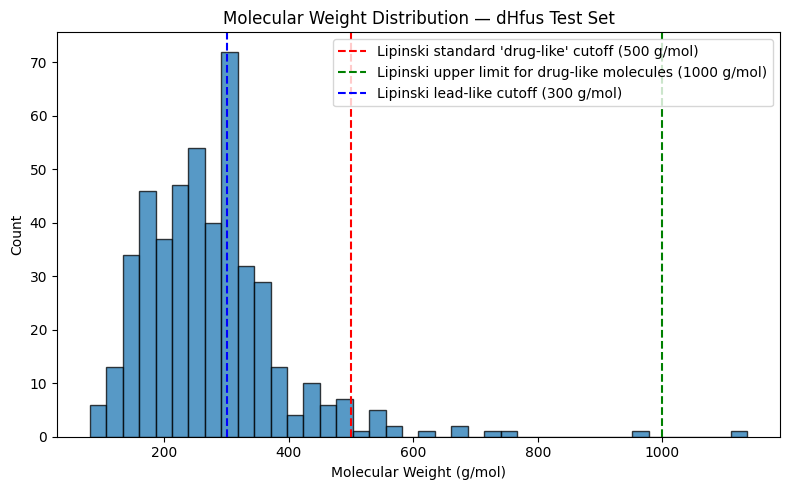

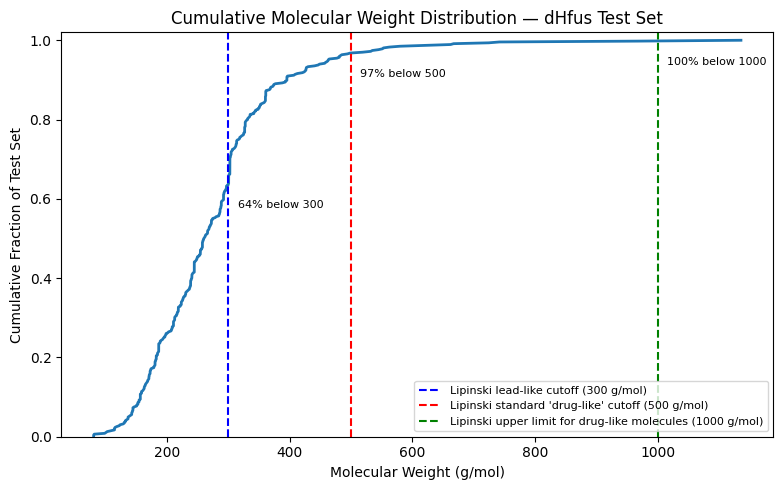

In [2]:
#PLOTTING OF MW DISTRIBUTION FOR CONTEXT
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(baseline_predictions["MW"], bins=40, edgecolor="black", alpha=0.75)
ax.axvline(500, color="red", linestyle="--", label="Lipinski standard 'drug-like' cutoff (500 g/mol)")
ax.axvline(1000, color="green", linestyle="--", label="Lipinski upper limit for drug-like molecules (1000 g/mol)")
ax.axvline(300, color="blue", linestyle="--", label="Lipinski lead-like cutoff (300 g/mol)")

ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Count")
ax.set_title("Molecular Weight Distribution — dHfus Test Set")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_MW_distribution.png", dpi=150)
plt.show()

#CUMULATIVE FRACTION PLOT FOR MOLECULAR WEIGHT — SHOWS WHAT FRACTION OF THE TEST SET FALLS BELOW EACH MW VALUE,
#USING THE SAME LIPINSKI REFERENCE LINES AS THE DISTRIBUTION PLOT ABOVE
sorted_mw = np.sort(baseline_predictions["MW"])
cumulative_frac_mw = np.arange(1, len(sorted_mw) + 1) / len(sorted_mw)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sorted_mw, cumulative_frac_mw, linewidth=2)

for cutoff, color, label in [(300, "blue", "Lipinski lead-like cutoff (300 g/mol)"),
                              (500, "red", "Lipinski standard 'drug-like' cutoff (500 g/mol)"),
                              (1000, "green", "Lipinski upper limit for drug-like molecules (1000 g/mol)")]:
    frac_below = (baseline_predictions["MW"] <= cutoff).mean()
    ax.axvline(cutoff, color=color, linestyle="--", label=label)
    ax.annotate(f"{frac_below:.0%} below {cutoff}", xy=(cutoff, frac_below),
                xytext=(cutoff + 15, frac_below - 0.06), fontsize=8)

ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Cumulative Fraction of Test Set")
ax.set_title("Cumulative Molecular Weight Distribution — dHfus Test Set")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("plots_dHfus_MW_cumulative.png", dpi=150)
plt.show()



mw_lipinski_bin
Lead-like (<300)       296
Drug-like (300-500)    154
Extended (500-1000)     14
>1000                    1
Name: count, dtype: int64
             n  mw_range  mean_abs_error  median_abs_error  mean_rel_error
mw_bin                                                                    
Small MW   158    80-223        1.295504          0.963099      102.617723
Medium MW  156   224-302        1.322356          0.920059       24.775425
Large MW   151  302-1136        1.786977          1.279111       23.851810


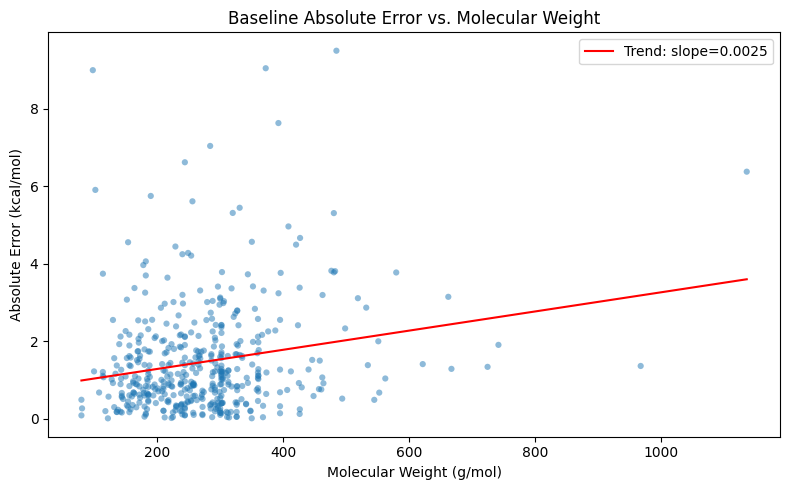

Correlation between MW and absolute error: 0.202


In [3]:
#THE CODE BELOW DOES NOT PREIDCT ANYTHING NEW. IT SIMPLY TAKES THE COMPLETE BASELINE PREDICTIONS ALONG WITH TRUE VALUES AND CORRESPONDING ERROR,
#BEFORE BINNING BASED ON MW AND PLOTTING TO INVESTIGATE WHETHER THERE IS A TREND BETWEEN MW AND ERROR.
#BINS BASED ON TERTILES OF THE ACTUAL TEST-SET MW DISTRIBUTION

#CHECKING TO SEE HOW MANY MOLECULES FALL INTO EACH LIPINSKI CATEGORY
#THE CATAGORIES ARE HIGHLY UNBALANCED, THEREFORE A DIFFERENT BINNING STRATEGY MUST BE USED.
lipinski_bins = [0, 300, 500, 1000, np.inf]
lipinski_labels = ["Lead-like (<300)", "Drug-like (300-500)", "Extended (500-1000)", ">1000"]
baseline_predictions["mw_lipinski_bin"] = pd.cut(baseline_predictions["MW"], bins=lipinski_bins, labels=lipinski_labels)
print(baseline_predictions["mw_lipinski_bin"].value_counts())

mw_bins = baseline_predictions["MW"].quantile([0, 1/3, 2/3, 1]).values      #SPLITS THE BASELINE PREDICTION DATA INTO 3 BINS BASED ON MW
mw_labels = ["Small MW", "Medium MW", "Large MW"]
baseline_predictions["mw_bin"] = pd.cut(baseline_predictions["MW"], bins=mw_bins, labels=mw_labels, include_lowest=True)

mw_error_table = baseline_predictions.groupby("mw_bin", observed=True).agg(
    n=("abs_error", "count"),
    mw_range=("MW", lambda x: f"{x.min():.0f}-{x.max():.0f}"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
    mean_rel_error=("rel_error_pct", "mean"),
)
print(mw_error_table)

#SCATTER OF ERROR VS MW, CONTINUOUS TREND 
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["MW"], baseline_predictions["abs_error"], alpha=0.5, s=20, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["MW"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["MW"].min(), baseline_predictions["MW"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. Molecular Weight")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_MW.png", dpi=150)
plt.show()

corr = np.corrcoef(baseline_predictions["MW"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between MW and absolute error: {corr:.3f}")


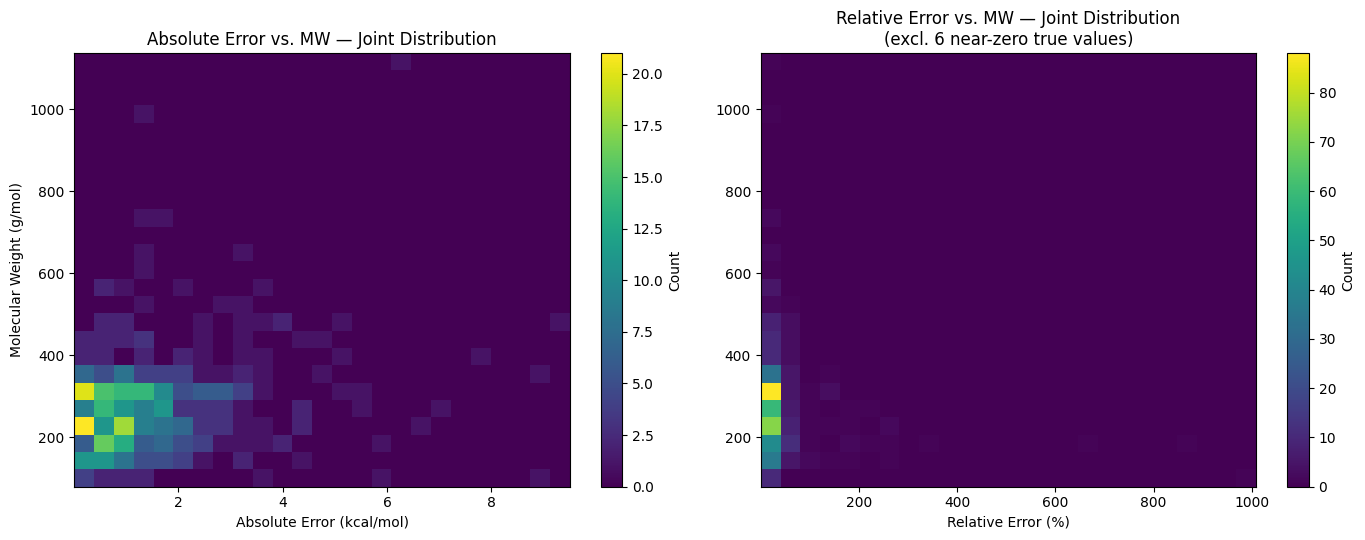

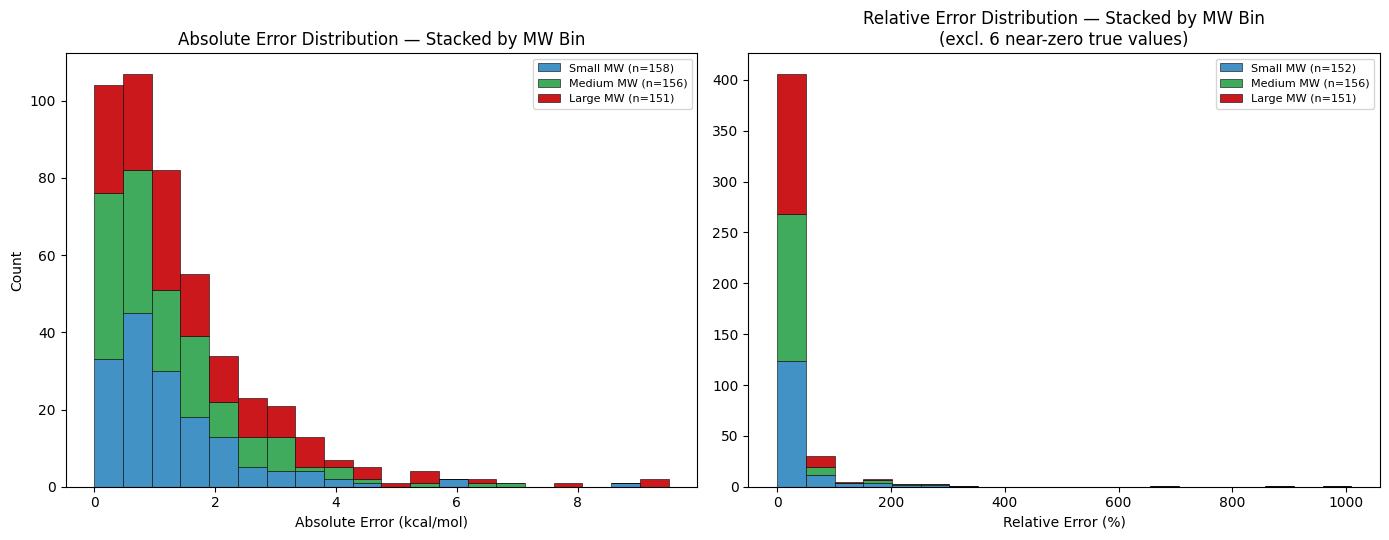

In [10]:
#2D HISTOGRAM: ABSOLUTE/RELATIVE ERROR (X) VS MW (Y), COLOR = COUNT OF MOLECULES IN THAT (ERROR, MW) CELL —
#SHOWS THE FULL JOINT DISTRIBUTION OF ERROR AND MW SIMULTANEOUSLY, RATHER THAN COLLAPSING MW INTO DISCRETE BINS

near_zero_threshold = 0.5
near_zero_mask = baseline_predictions["y_true"].abs() < near_zero_threshold

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

#ABSOLUTE ERROR VS MW
h1 = axes[0].hist2d(baseline_predictions["abs_error"], baseline_predictions["MW"],
                     bins=[25, 25], cmap="viridis")
cbar1 = plt.colorbar(h1[3], ax=axes[0])
cbar1.set_label("Count")
axes[0].set_xlabel("Absolute Error (kcal/mol)")
axes[0].set_ylabel("Molecular Weight (g/mol)")
axes[0].set_title("Absolute Error vs. MW — Joint Distribution")

#RELATIVE ERROR VS MW (EXCLUDING NEAR-ZERO TRUE VALUES)
rel_subset = baseline_predictions[~near_zero_mask]
h2 = axes[1].hist2d(rel_subset["rel_error_pct"], rel_subset["MW"],
                     bins=[25, 25], cmap="viridis")
cbar2 = plt.colorbar(h2[3], ax=axes[1])
cbar2.set_label("Count")
axes[1].set_xlabel("Relative Error (%)")
axes[1].set_title(f"Relative Error vs. MW — Joint Distribution\n(excl. {near_zero_mask.sum()} near-zero true values)")

plt.tight_layout()
plt.savefig("plots_dHfus_error_MW_2Dhist.png", dpi=150)
plt.show()


#STACKED HISTOGRAM: STANDARD ERROR HISTOGRAM, WITH EACH BAR SEGMENTED BY MW BIN —
#SHOWS THE OVERALL ERROR DISTRIBUTION WHILE ALSO REVEALING WHICH MW GROUP CONTRIBUTES TO EACH ERROR RANGE

near_zero_threshold = 0.5
near_zero_mask = baseline_predictions["y_true"].abs() < near_zero_threshold

mw_bin_order = ["Small MW", "Medium MW", "Large MW"]
mw_bin_colors = ["#4292c6", "#41ab5d", "#cb181d"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

#ABSOLUTE ERROR — STACKED BY MW BIN
abs_error_by_bin = [baseline_predictions.loc[baseline_predictions["mw_bin"] == b, "abs_error"] for b in mw_bin_order]
axes[0].hist(abs_error_by_bin, bins=20, stacked=True, color=mw_bin_colors,
             label=[f"{b} (n={len(d)})" for b, d in zip(mw_bin_order, abs_error_by_bin)],
             edgecolor="black", linewidth=0.4)
axes[0].set_xlabel("Absolute Error (kcal/mol)")
axes[0].set_ylabel("Count")
axes[0].set_title("Absolute Error Distribution — Stacked by MW Bin")
axes[0].legend(fontsize=8)

#RELATIVE ERROR — STACKED BY MW BIN (EXCLUDING NEAR-ZERO TRUE VALUES)
rel_subset = baseline_predictions[~near_zero_mask]
rel_error_by_bin = [rel_subset.loc[rel_subset["mw_bin"] == b, "rel_error_pct"] for b in mw_bin_order]
axes[1].hist(rel_error_by_bin, bins=20, stacked=True, color=mw_bin_colors,
             label=[f"{b} (n={len(d)})" for b, d in zip(mw_bin_order, rel_error_by_bin)],
             edgecolor="black", linewidth=0.4)
axes[1].set_xlabel("Relative Error (%)")
axes[1].set_title(f"Relative Error Distribution — Stacked by MW Bin\n(excl. {near_zero_mask.sum()} near-zero true values)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("plots_dHfus_error_MW_stacked_hist.png", dpi=150)
plt.show()

In [ ]:
#PART 1.2: RETRAINING THE BASELINE MODEL BASED ON MW BINS, TO SEE IF TRAINING ON SMALL OR LARGE MOLECULES SPECIFICALY IMPORVES PERFORMANCE.

#LOAD FULL DATASET FRESH (NOT JUST TEST SET) TO GET TRAIN-ELIGIBLE MOLECULES FOR SUBSET FILTERING
input_path = Path("RAW DATA") / "dHfus_DB.csv"
smiles_column = "smiles"
target_columns = ["dHfus [kcal/mol]"]

df_clean, all_data, mols = load_and_clean_data(input_path, smiles_column, target_columns)
df_clean["MW"] = df_clean[smiles_column].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))

#DEFINE SMALL/LARGE SUBSETS BASED ON THE SAME TERTILE CUTOFFS AS BEFORE
mw_cutoffs = df_clean["MW"].quantile([1/3, 2/3]).values
small_mask = df_clean["MW"] <= mw_cutoffs[0]
large_mask = df_clean["MW"] >= mw_cutoffs[1]

print(f"Small MW subset: {small_mask.sum()} molecules (MW <= {mw_cutoffs[0]:.0f})")
print(f"Large MW subset: {large_mask.sum()} molecules (MW >= {mw_cutoffs[1]:.0f})")

small_indices = df_clean[small_mask].index.tolist()
large_indices = df_clean[large_mask].index.tolist()

small_data = [all_data[i] for i in small_indices]
small_mols = [mols[i] for i in small_indices]
large_data = [all_data[i] for i in large_indices]
large_mols = [mols[i] for i in large_indices]

mw_subset_results = {}

#TRAINS THE MODEL ON SMALL AND LARGE MOLECULES SEPARATELY, USING THE SAME SPLIT STRATEGY AS BEFORE, AND EVALUATES PERFORMANCE ON THE TEST SET.

for subset_name, subset_data, subset_mols in [("small_MW", small_data, small_mols), ("large_MW", large_data, large_mols)]:
    subset_splits = build_splits(subset_data, subset_mols, split_types=("scaffold_balanced",))
    result = build_and_train_mpnn(
        subset_splits["scaffold_balanced"]["train"],
        subset_splits["scaffold_balanced"]["val"],
        subset_splits["scaffold_balanced"]["test"],
        dropout=0.4,
        run_name=f"dHfus_MW_{subset_name}",
    )
    preds = predict_test_set(result, run_name=f"dHfus_MW_{subset_name}")
    mw_subset_results[subset_name] = {"result": result, "predictions": preds}
    print(f"{subset_name}: MAE={preds['abs_error'].mean():.3f}, RMSE={np.sqrt((preds['abs_error']**2).mean()):.3f}")


comparison_rows = [{
    "Model": "Full baseline (all MW)",
    "MAE": baseline_predictions["abs_error"].mean(),
    "RMSE": np.sqrt((baseline_predictions["abs_error"] ** 2).mean()),
    "N_test": len(baseline_predictions),
}]
for subset_name, data_dict in mw_subset_results.items():
    p = data_dict["predictions"]
    comparison_rows.append({
        "Model": f"Trained on {subset_name} only",
        "MAE": p["abs_error"].mean(),
        "RMSE": np.sqrt((p["abs_error"] ** 2).mean()),
        "N_test": len(p),
    })

mw_comparison_df = pd.DataFrame(comparison_rows)
print(mw_comparison_df.to_string(index=False))
mw_comparison_df.to_csv("dHfus_MW_subset_comparison.csv", index=False)


[08:19:04] WARNING: not removing hydrogen atom without neighbors
[08:19:04] WARNING: not removing hydrogen atom without neighbors
[08:19:04] WARNING: not removing hydrogen atom without neighbors
[08:19:04] WARNING: not removing hydrogen atom without neighbors
[08:19:04] WARNING: not removing hydrogen atom without neighbors
[08:19:04] WARNING: not removing hydrogen atom without neighbors
[08:19:04] WARNING: not removing hydrogen atom without neighbors
[08:19:04] Unusual charge on atom 6 number of radical electrons set to zero


Loaded 5184 rows, dropped 527 with missing/invalid target, smiles, or stereo issues, 4657 remain


[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] Unusual charge on atom 6 number of radical electrons set to zero
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:05] WARNING: not removing hydrogen atom without neighbors
[08:19:06] Unu

Small MW subset: 1555 molecules (MW <= 176)
Large MW subset: 1553 molecules (MW >= 283)


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\astartes\samplers\extrapolation\scaffold.py:48: NoMatchingScaffold: No matching scaffold was found for the 590 molecules corresponding to indices {2, 4, 5, 9, 11, 17, 22, 23, 27, 28, 32, 33, 34, 35, 37, 38, 41, 42, 56, 63, 65, 66, 67, 72, 74, 75, 76, 77, 79, 80, 83, 86, 88, 93, 94, 95, 101, 107, 111, 113, 114, 115, 121, 123, 128, 129, 131, 136, 143, 144, 149, 152, 156, 159, 162, 165, 169, 176, 177, 182, 183, 185, 188, 191, 192, 198, 200, 209, 212, 219, 222, 227, 232, 233, 235, 239, 242, 243, 250, 252, 255, 257, 258, 259, 260, 264, 265, 266, 272, 273, 275, 277, 278, 286, 292, 301, 302, 303, 306, 311, 312, 316, 319, 321, 322, 325, 326, 329, 332, 334, 336, 341, 342, 345, 347, 355, 357, 358, 359, 360, 363, 367, 370, 371, 378, 379, 381, 382, 388, 390, 394, 397, 399, 404, 405, 406, 411, 413, 415, 416, 425, 427, 430, 432, 434, 436, 439, 443, 446, 449, 450, 453, 455, 460, 461, 462, 465, 466, 469, 471, 478, 479, 480

scaffold_balanced: train=1245, val=155, test=155


... (23 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/mae          │    2.5296781063079834     │
│         test/rmse         │     3.501488447189331     │
└───────────────────────────┴───────────────────────────┘

Output()

c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


large_MW: MAE=2.530, RMSE=3.501
                   Model      MAE     RMSE  N_test
  Full baseline (all MW) 1.464109 2.014384     465
Trained on small_MW only 1.194330 2.064042     155
Trained on large_MW only 2.529678 3.501488     155


Small MW training set size: 1555
Large MW training set size: 1553


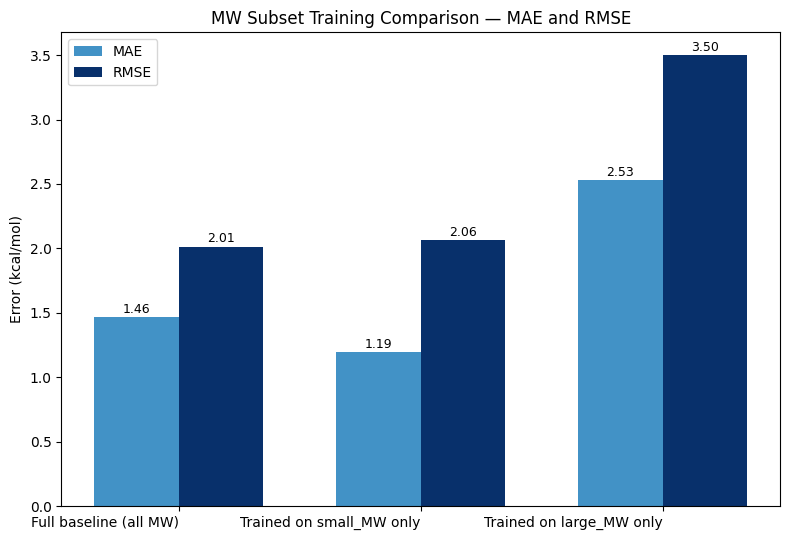

In [11]:

print(f"Small MW training set size: {len(small_data)}")
print(f"Large MW training set size: {len(large_data)}")

#BAR CHART COMPARING MAE AND RMSE ACROSS THE THREE MODELS: FULL BASELINE, SMALL-MW-ONLY, LARGE-MW-ONLY
fig, ax = plt.subplots(figsize=(8, 5.5))

x = np.arange(len(mw_comparison_df))
width = 0.35

bars_mae = ax.bar(x - width/2, mw_comparison_df["MAE"], width, label="MAE", color="#4292c6")
bars_rmse = ax.bar(x + width/2, mw_comparison_df["RMSE"], width, label="RMSE", color="#08306b")

#ANNOTATE EACH BAR WITH ITS EXACT VALUE FOR EASY READING
for bars in [bars_mae, bars_rmse]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(mw_comparison_df["Model"], rotation=0, ha="right")
ax.set_ylabel("Error (kcal/mol)")
ax.set_title("MW Subset Training Comparison — MAE and RMSE")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_MW_subset_comparison.png", dpi=150)
plt.show()



         HB_total  rotatable_bonds
count  465.000000       465.000000
mean     2.800000         2.686022
std      2.574075         4.886240
min      0.000000         0.000000
25%      0.000000         1.000000
50%      3.000000         2.000000
75%      4.000000         3.000000
max     19.000000        69.000000
                    n  mean_abs_error  median_abs_error
hb_bin                                                 
Low H-bonding     157        1.423280          1.009953
Medium H-bonding  209        1.416062          1.052957
High H-bonding     99        1.630291          1.220677


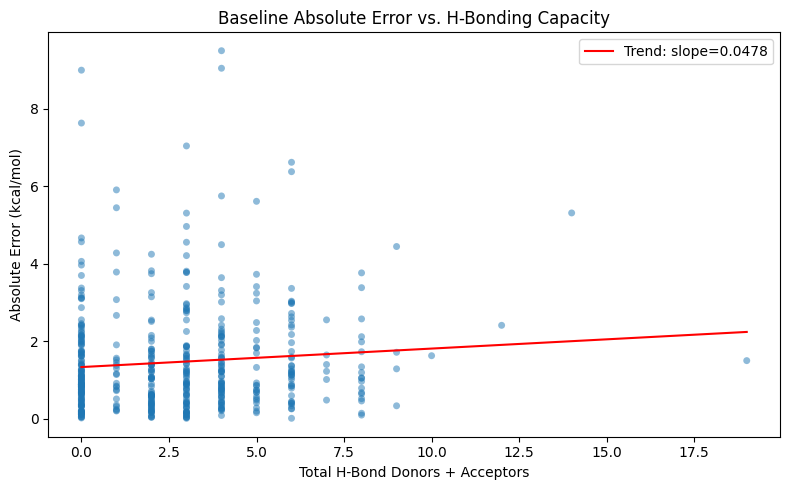

Correlation between H-bonding capacity and absolute error: 0.089
                        n  mean_abs_error  median_abs_error
rb_bin                                                     
Rigid                 222        1.362151          0.938464
Moderate flexibility  131        1.431628          1.179716
Highly flexible       112        1.704196          1.273169


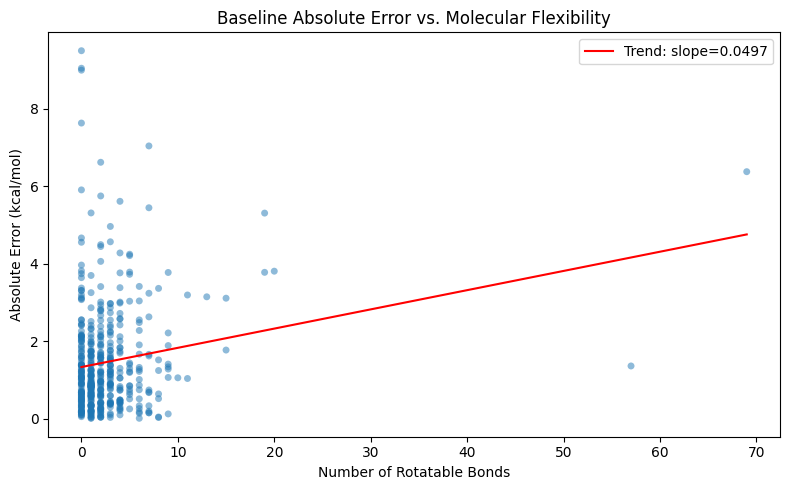

Correlation between rotatable bonds and absolute error: 0.175


In [ ]:
#PART 2: HYDROGEN BONDING ANALYSIS & PART 3: FLEXIBILITY ANALYSIS


from rdkit.Chem import Lipinski

#DETERMINES THE NUMBER OF HBA AND HBD FOR EACH MOLECULE
baseline_predictions["HBD"] = baseline_predictions["smiles"].apply(lambda s: Lipinski.NumHDonors(Chem.MolFromSmiles(s)))
baseline_predictions["HBA"] = baseline_predictions["smiles"].apply(lambda s: Lipinski.NumHAcceptors(Chem.MolFromSmiles(s)))
baseline_predictions["HB_total"] = baseline_predictions["HBD"] + baseline_predictions["HBA"]

#DETERMINES THE NUMBER OF ROTATABLE BONDS FOR EACH MOLECULE
baseline_predictions["rotatable_bonds"] = baseline_predictions["smiles"].apply(
    lambda s: Descriptors.NumRotatableBonds(Chem.MolFromSmiles(s))
)

print(baseline_predictions[["HB_total", "rotatable_bonds"]].describe())

#BIN BY H-BONDING CAPACITY (TERTILES OF ACTUAL DATA DISTRIBUTION)
hb_bins = baseline_predictions["HB_total"].quantile([0, 1/3, 2/3, 1]).unique()
if len(hb_bins) < 4:   #GUARDS AGAINST DUPLICATE BIN EDGES IF MANY MOLECULES SHARE THE SAME HB_total VALUE
    hb_bins = [baseline_predictions["HB_total"].min() - 0.5, 1.5, 3.5, baseline_predictions["HB_total"].max() + 0.5]
hb_labels = ["Low H-bonding", "Medium H-bonding", "High H-bonding"]
baseline_predictions["hb_bin"] = pd.cut(baseline_predictions["HB_total"], bins=hb_bins, labels=hb_labels, include_lowest=True)

hb_error_table = baseline_predictions.groupby("hb_bin", observed=True).agg(
    n=("abs_error", "count"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
)
print(hb_error_table)

#SCATTER PLOT OF BASELINE ABSOLUTE ERROR VS H-BONDING CAPACITY, WITH A LINEAR TRENDLINE FITTED
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["HB_total"], baseline_predictions["abs_error"], alpha=0.5, s=25, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["HB_total"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["HB_total"].min(), baseline_predictions["HB_total"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Total H-Bond Donors + Acceptors")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. H-Bonding Capacity")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_HB.png", dpi=150)
plt.show()

corr_hb = np.corrcoef(baseline_predictions["HB_total"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between H-bonding capacity and absolute error: {corr_hb:.3f}")

rb_bins = baseline_predictions["rotatable_bonds"].quantile([0, 1/3, 2/3, 1]).unique()
if len(rb_bins) < 4:
    rb_bins = [baseline_predictions["rotatable_bonds"].min() - 0.5, 2.5, 6.5, baseline_predictions["rotatable_bonds"].max() + 0.5]
rb_labels = ["Rigid", "Moderate flexibility", "Highly flexible"]
baseline_predictions["rb_bin"] = pd.cut(baseline_predictions["rotatable_bonds"], bins=rb_bins, labels=rb_labels, include_lowest=True)

rb_error_table = baseline_predictions.groupby("rb_bin", observed=True).agg(
    n=("abs_error", "count"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
)
print(rb_error_table)


#SCATTER PLOT OF BASELINE ABSOLUTE ERROR VS NUMBER OF ROTATABLE BONDS, WITH A LINEAR TRENDLINE FITTED
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"], alpha=0.5, s=25, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["rotatable_bonds"].min(), baseline_predictions["rotatable_bonds"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Number of Rotatable Bonds")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. Molecular Flexibility")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_rotatable.png", dpi=150)
plt.show()

corr_rb = np.corrcoef(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between rotatable bonds and absolute error: {corr_rb:.3f}")



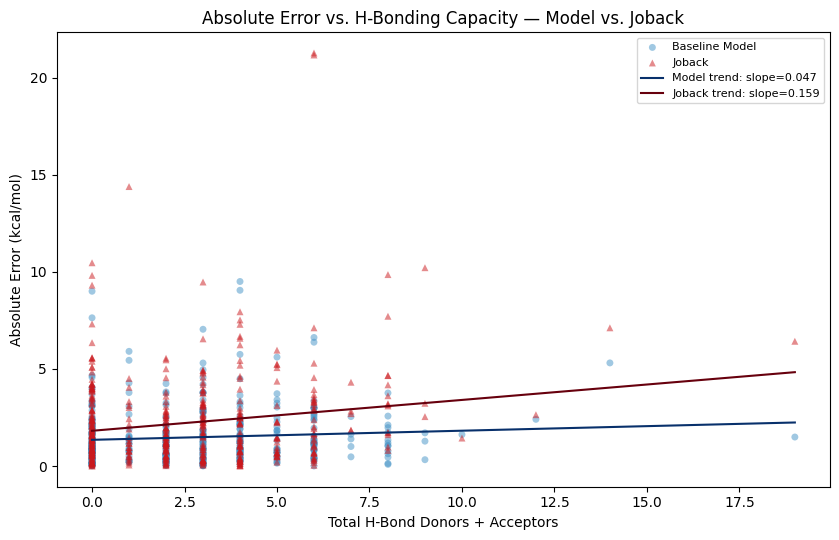

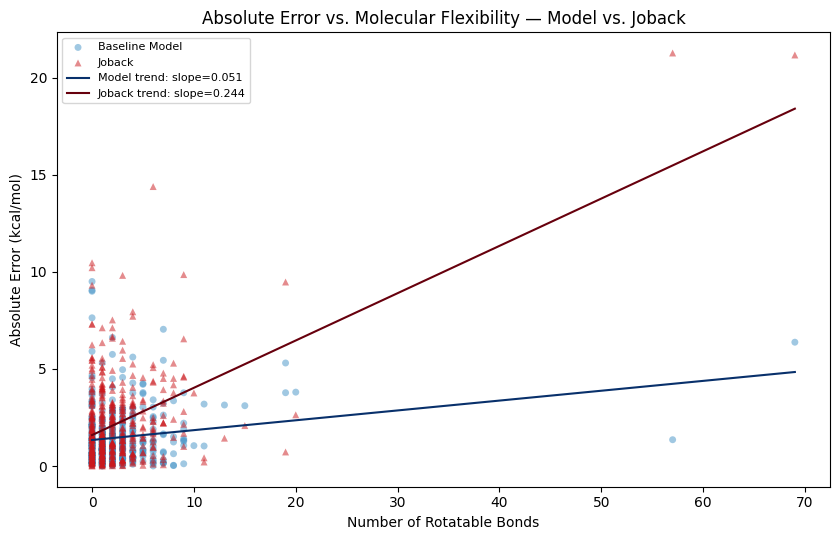

Joback predictions available for 438 / 465 test molecules
                    n  model_mean_error  joback_mean_error  model_advantage
hb_bin                                                                     
Low H-bonding     157          1.423280           2.125914         0.702635
Medium H-bonding  193          1.452733           1.989691         0.536958
High H-bonding     88          1.635048           3.012478         1.377430


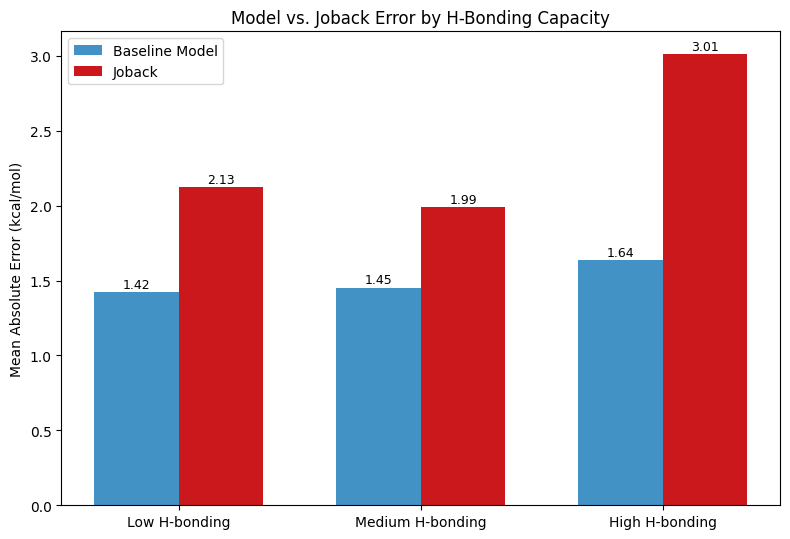

                        n  model_mean_error  joback_mean_error  \
rb_bin                                                           
Rigid                 217          1.363735           2.009628   
Moderate flexibility  116          1.471382           2.053552   
Highly flexible       105          1.724817           2.938815   

                      model_advantage  
rb_bin                                 
Rigid                        0.645893  
Moderate flexibility         0.582170  
Highly flexible              1.213999  


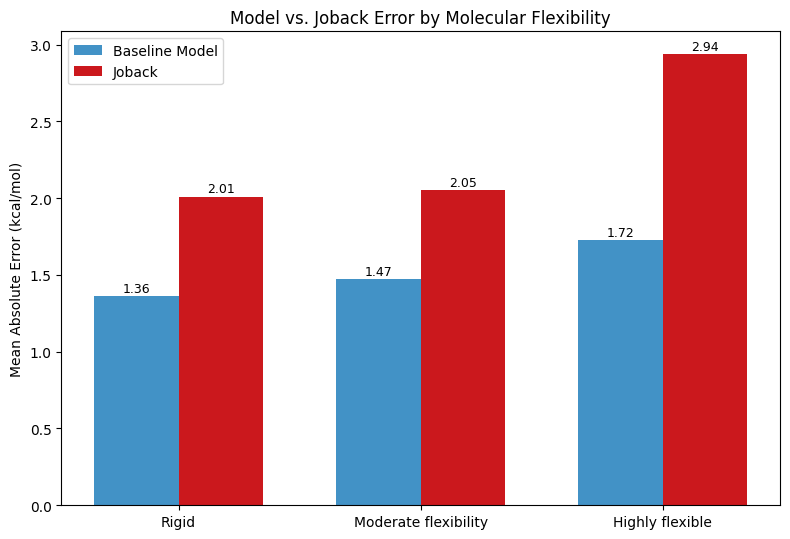

In [16]:
#H-BONDING VS ABSOLUTE ERROR — MODEL AND JOBACK OVERLAID
fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.scatter(comparison_data["HB_total"], comparison_data["abs_error"], alpha=0.5, s=25,
           color="#4292c6", marker="o", edgecolor="none", label="Baseline Model")
ax.scatter(comparison_data["HB_total"], comparison_data["joback_abs_error"], alpha=0.5, s=25,
           color="#cb181d", marker="^", edgecolor="none", label="Joback")

#TRENDLINE FOR EACH SERIES
for col, color in [("abs_error", "#08306b"), ("joback_abs_error", "#67000d")]:
    slope, intercept = np.polyfit(comparison_data["HB_total"], comparison_data[col], 1)
    x_line = np.array([comparison_data["HB_total"].min(), comparison_data["HB_total"].max()])
    ax.plot(x_line, slope * x_line + intercept, color=color, linewidth=1.5,
            label=f"{'Model' if col=='abs_error' else 'Joback'} trend: slope={slope:.3f}")

ax.set_xlabel("Total H-Bond Donors + Acceptors")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Absolute Error vs. H-Bonding Capacity — Model vs. Joback")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_HB_with_joback.png", dpi=150)
plt.show()

#ROTATABLE BONDS VS ABSOLUTE ERROR — MODEL AND JOBACK OVERLAID
fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.scatter(comparison_data["rotatable_bonds"], comparison_data["abs_error"], alpha=0.5, s=25,
           color="#4292c6", marker="o", edgecolor="none", label="Baseline Model")
ax.scatter(comparison_data["rotatable_bonds"], comparison_data["joback_abs_error"], alpha=0.5, s=25,
           color="#cb181d", marker="^", edgecolor="none", label="Joback")

for col, color in [("abs_error", "#08306b"), ("joback_abs_error", "#67000d")]:
    slope, intercept = np.polyfit(comparison_data["rotatable_bonds"], comparison_data[col], 1)
    x_line = np.array([comparison_data["rotatable_bonds"].min(), comparison_data["rotatable_bonds"].max()])
    ax.plot(x_line, slope * x_line + intercept, color=color, linewidth=1.5,
            label=f"{'Model' if col=='abs_error' else 'Joback'} trend: slope={slope:.3f}")

ax.set_xlabel("Number of Rotatable Bonds")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Absolute Error vs. Molecular Flexibility — Model vs. Joback")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_rotatable_with_joback.png", dpi=150)
plt.show()



#TESTS WHETHER THE MODEL SPECIFICALLY OUTPERFORMS JOBACK IN THE REGIME WHERE JOBACK IS KNOWN TO STRUGGLE
#(INTERMOLECULAR EFFECTS LIKE H-BONDING, WHICH A PURELY ADDITIVE FRAGMENT-BASED METHOD CANNOT REPRESENT)

from chemprop_utils import joback_predict_dHfus

#COMPUTE JOBACK'S PREDICTION AND ERROR FOR EVERY TEST-SET MOLECULE (SKIP IF UNASSIGNABLE GROUPS)
baseline_predictions["joback_pred"] = baseline_predictions["smiles"].apply(joback_predict_dHfus)
joback_valid_mask = baseline_predictions["joback_pred"].notna()
print(f"Joback predictions available for {joback_valid_mask.sum()} / {len(baseline_predictions)} test molecules")

baseline_predictions["joback_abs_error"] = np.abs(baseline_predictions["joback_pred"] - baseline_predictions["y_true"])

#RESTRICT COMPARISON TO MOLECULES WHERE BOTH THE MODEL AND JOBACK HAVE A VALID PREDICTION — FAIR, MATCHED COMPARISON
comparison_data = baseline_predictions[joback_valid_mask].copy()

hb_comparison_table = comparison_data.groupby("hb_bin", observed=True).agg(
    n=("abs_error", "count"),
    model_mean_error=("abs_error", "mean"),
    joback_mean_error=("joback_abs_error", "mean"),
)
hb_comparison_table["model_advantage"] = hb_comparison_table["joback_mean_error"] - hb_comparison_table["model_mean_error"]
print(hb_comparison_table)

#GROUPED BAR CHART — MODEL VS JOBACK ERROR PER H-BONDING BIN
fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(hb_comparison_table))
width = 0.35
bars_model = ax.bar(x - width/2, hb_comparison_table["model_mean_error"], width, label="Baseline Model", color="#4292c6")
bars_joback = ax.bar(x + width/2, hb_comparison_table["joback_mean_error"], width, label="Joback", color="#cb181d")
for bars in [bars_model, bars_joback]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(hb_comparison_table.index)
ax.set_ylabel("Mean Absolute Error (kcal/mol)")
ax.set_title("Model vs. Joback Error by H-Bonding Capacity")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_model_vs_joback_by_HB.png", dpi=150)
plt.show()

rb_comparison_table = comparison_data.groupby("rb_bin", observed=True).agg(
    n=("abs_error", "count"),
    model_mean_error=("abs_error", "mean"),
    joback_mean_error=("joback_abs_error", "mean"),
)
rb_comparison_table["model_advantage"] = rb_comparison_table["joback_mean_error"] - rb_comparison_table["model_mean_error"]
print(rb_comparison_table)

fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(rb_comparison_table))
width = 0.35
bars_model = ax.bar(x - width/2, rb_comparison_table["model_mean_error"], width, label="Baseline Model", color="#4292c6")
bars_joback = ax.bar(x + width/2, rb_comparison_table["joback_mean_error"], width, label="Joback", color="#cb181d")
for bars in [bars_model, bars_joback]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(rb_comparison_table.index)
ax.set_ylabel("Mean Absolute Error (kcal/mol)")
ax.set_title("Model vs. Joback Error by Molecular Flexibility")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_model_vs_joback_by_rotatable.png", dpi=150)
plt.show()


In [ ]:


#EFFECT OF H-BONDING AND FLEXIBILITY ON THE TRUE ΔHfus VALUE ITSELF 

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

#H-BONDING VS TRUE ΔHfus
axes[0].scatter(baseline_predictions["HB_total"], baseline_predictions["y_true"], alpha=0.5, s=25, edgecolor="none")
slope_hb, intercept_hb = np.polyfit(baseline_predictions["HB_total"], baseline_predictions["y_true"], 1)
x_hb = np.array([baseline_predictions["HB_total"].min(), baseline_predictions["HB_total"].max()])
axes[0].plot(x_hb, slope_hb * x_hb + intercept_hb, color="red", linewidth=1.5, label=f"Trend: slope={slope_hb:.3f}")
axes[0].set_xlabel("Total H-Bond Donors + Acceptors")
axes[0].set_ylabel("True ΔHfus (kcal/mol)")
axes[0].set_title("H-Bonding Capacity vs. True ΔHfus")
axes[0].legend()

#ROTATABLE BONDS VS TRUE ΔHfus
axes[1].scatter(baseline_predictions["rotatable_bonds"], baseline_predictions["y_true"], alpha=0.5, s=25, edgecolor="none", color="orange")
slope_rb, intercept_rb = np.polyfit(baseline_predictions["rotatable_bonds"], baseline_predictions["y_true"], 1)
x_rb = np.array([baseline_predictions["rotatable_bonds"].min(), baseline_predictions["rotatable_bonds"].max()])
axes[1].plot(x_rb, slope_rb * x_rb + intercept_rb, color="red", linewidth=1.5, label=f"Trend: slope={slope_rb:.3f}")
axes[1].set_xlabel("Number of Rotatable Bonds")
axes[1].set_ylabel("True ΔHfus (kcal/mol)")
axes[1].set_title("Flexibility vs. True ΔHfus")
axes[1].legend()

plt.tight_layout()
plt.savefig("plots_dHfus_true_value_vs_HB_and_flexibility.png", dpi=150)
plt.show()

corr_hb_true = np.corrcoef(baseline_predictions["HB_total"], baseline_predictions["y_true"])[0, 1]
corr_rb_true = np.corrcoef(baseline_predictions["rotatable_bonds"], baseline_predictions["y_true"])[0, 1]
print(f"Correlation: H-bonding capacity vs true ΔHfus:  {corr_hb_true:+.3f}")
print(f"Correlation: rotatable bonds vs true ΔHfus:     {corr_rb_true:+.3f}")

#DO HB/FLEXIBILITY CORRELATE WITH MW 
corr_hb_mw = np.corrcoef(baseline_predictions["HB_total"], baseline_predictions["MW"])[0, 1]
corr_rb_mw = np.corrcoef(baseline_predictions["rotatable_bonds"], baseline_predictions["MW"])[0, 1]
print(f"Correlation: H-bonding capacity vs MW:  {corr_hb_mw:+.3f}")
print(f"Correlation: rotatable bonds vs MW:      {corr_rb_mw:+.3f}")